# Лабораторная работа № 1. Полносвязные нейронные сети и классификация изображений

**Тема:** многослойный перцептрон (MLP), нелинейные функции активации, обучение и оценка качества классификации.

**Цель:** научиться строить полносвязные нейронные сети, исследовать их архитектуру и оценивать качество классификации с помощью стандартных метрик.

В работе мы построим классификатор изображений рукописных цифр MNIST. Сначала разберём, как линейные слои объединяются в MLP, почему между ними нужны нелинейные функции активации и как выход классификатора преобразуется в вероятности. Затем подготовим изображения, обучим сеть с помощью PyTorch Lightning и оценим качество на независимой тестовой выборке.

In [ ]:
# Проверяем версии библиотек и выбираем устройство, на котором будут выполняться вычисления.
import sys
import platform
import torch

# Сначала фиксируем версии среды: это помогает понять, какие возможности PyTorch и CUDA доступны.
print(f"Python: {sys.version.split()[0]}")
print(f"Платформа: {platform.platform()}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA доступна: {torch.cuda.is_available()}")
print(f"CUDA-сборка PyTorch: {torch.version.cuda}")

# Выбираем единое устройство для дальнейших вычислений; при отсутствии CUDA используем CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство для вычислений: {device}")

# Дополнительные сведения о видеокарте выводим только тогда, когда CUDA действительно доступна.
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA-устройств: {torch.cuda.device_count()}")

## Что было рассмотрено в лабораторной работе № 0

В предыдущей работе мы познакомились с `torch.nn.Linear`. Для одного объекта линейный слой выполняет преобразование:

$$
\mathbf{y}=W\mathbf{x}+\mathbf{b},
$$

где $\mathbf{x}$ - входной вектор признаков, $W$ - матрица обучаемых весов, $\mathbf{b}$ - вектор смещений, а $\mathbf{y}$ - результат преобразования.

В PyTorch такой слой создаётся как `nn.Linear(in_features, out_features)`. В ходе обучения оптимизатор изменяет веса и смещения, чтобы уменьшать функцию потерь. Теперь объединим несколько линейных слоёв в одну модель.

## Многослойный перцептрон (MLP)

**Многослойный перцептрон** (*Multilayer Perceptron, MLP*) - сеть прямого распространения, состоящая из нескольких полносвязных слоёв. Каждый нейрон следующего слоя получает значения от всех нейронов предыдущего слоя.

Скрытый слой сначала выполняет линейное преобразование, а затем применяет функцию активации:

$$
\mathbf{a}^{(l)}=W^{(l)}\mathbf{h}^{(l-1)}+\mathbf{b}^{(l)},\qquad
\mathbf{h}^{(l)}=\varphi(\mathbf{a}^{(l)}).
$$

Таким образом, MLP - это **композиция линейных преобразований и нелинейностей**. Например, для двух скрытых слоёв:

$$
f(\mathbf{x})=
W^{(3)}\varphi\left(
W^{(2)}\varphi(W^{(1)}\mathbf{x}+\mathbf{b}^{(1)})
+\mathbf{b}^{(2)}
\right)+\mathbf{b}^{(3)}.
$$

Каждый `Linear` обучает веса и смещения. Функция активации обычно не содержит обучаемых параметров: она меняет значения, передаваемые следующему слою.

### Почему недостаточно нескольких линейных слоёв подряд?

Композиция линейных преобразований сама остаётся линейным преобразованием. Поэтому несколько `nn.Linear`, между которыми нет нелинейностей, математически можно заменить одним линейным слоем. Нелинейные активации позволяют модели описывать более сложные зависимости и нелинейные границы между классами.

Если вход содержит $n_0$ признаков, а скрытые слои - $n_1$ и $n_2$ нейронов, архитектура записывается как:

$$
n_0\rightarrow n_1\rightarrow n_2\rightarrow n_{classes}.
$$

Для MNIST после преобразования изображения $28\times28$ в вектор получится 784 признака. Если сеть классифицирует десять цифр, выходной слой должен возвращать десять значений.

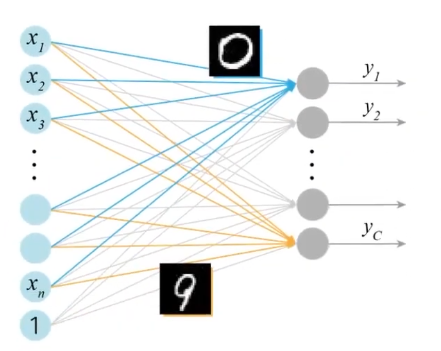

**Небольшое исследование.** Посчитайте число обучаемых параметров сети `784 → 128 → 64 → 10`. Для слоя `nn.Linear` используйте формулу:

$$
N_{parameters}=n_{in}\cdot n_{out}+n_{out}.
$$

Сравните результат с архитектурой `784 → 256 → 128 → 10`. Как меняется размер модели?

## Нелинейные функции активации

Функция активации применяется к выходу линейного слоя поэлементно. Она определяет, какие значения будут переданы следующему слою. Рассмотрим три распространённые функции: **ReLU**, **Sigmoid** и **Tanh**. Их диапазоны и производные влияют на скорость и устойчивость обучения.

### ReLU

Функция ReLU (*Rectified Linear Unit*) определяется так:

$$
\operatorname{ReLU}(x)=\max(0,x).
$$

Для отрицательных входов она возвращает ноль, а для положительных - исходное значение. Производная равна нулю при $x<0$ и единице при $x>0$ (в точке $x=0$ используется выбранное реализацией соглашение).

ReLU часто применяют в скрытых слоях MLP и CNN: она проста, быстро вычисляется и не насыщается на положительной полуоси. При этом нейрон может надолго «умереть», если его входы постоянно отрицательны: градиент через него будет равен нулю.

### Sigmoid

Сигмоидальная функция задаётся выражением:

$$
\sigma(x)=\frac{1}{1+e^{-x}},\qquad
\sigma'(x)=\sigma(x)(1-\sigma(x)).
$$

Значения Sigmoid лежат между 0 и 1. Поэтому её удобно интерпретировать как преобразование одного логита в вероятность в бинарной классификации. Однако при больших положительных или отрицательных значениях входа функция насыщается: её производная становится близкой к нулю.

В глубоких сетях многократное прохождение градиента через насыщенные сигмоиды может приводить к **затуханию градиента**. Кроме того, значения функции не центрированы относительно нуля.

### Tanh

Гиперболический тангенс определяется формулой:

$$
\tanh(x)=\frac{e^x-e^{-x}}{e^x+e^{-x}},\qquad
\tanh'(x)=1-\tanh^2(x).
$$

Диапазон значений - от $-1$ до $1$. В отличие от Sigmoid, Tanh центрирована относительно нуля. Однако на больших по модулю входах она также насыщается, а производная приближается к нулю. Поэтому проблема затухания градиента для неё тоже актуальна.

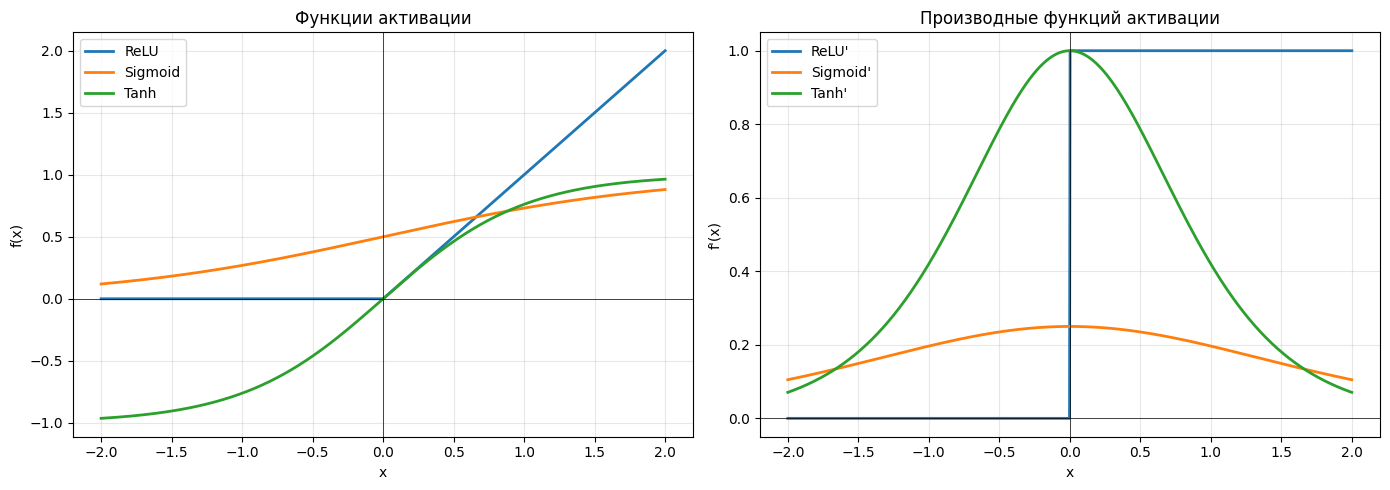

In [2]:
# Графики функций активации и их производных.
import numpy as np
import matplotlib.pyplot as plt

# Диапазон значений x.
x = np.linspace(-2, 2, 1000)

# Функции активации.
relu = np.maximum(0, x)
sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)

# Производные.
relu_derivative = np.where(x > 0, 1, 0)
sigmoid_derivative = sigmoid * (1 - sigmoid)
tanh_derivative = 1 - tanh**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(x, relu, label="ReLU", linewidth=2)
ax1.plot(x, sigmoid, label="Sigmoid", linewidth=2)
ax1.plot(x, tanh, label="Tanh", linewidth=2)

ax1.set_title("Функции активации")
ax1.set_xlabel("x")
ax1.set_ylabel("f(x)")
ax1.axhline(0, color="black", linewidth=0.5)
ax1.axvline(0, color="black", linewidth=0.5)
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(x, relu_derivative, label="ReLU'", linewidth=2)
ax2.plot(x, sigmoid_derivative, label="Sigmoid'", linewidth=2)
ax2.plot(x, tanh_derivative, label="Tanh'", linewidth=2)

ax2.set_title("Производные функций активации")
ax2.set_xlabel("x")
ax2.set_ylabel("f'(x)")
ax2.axhline(0, color="black", linewidth=0.5)
ax2.axvline(0, color="black", linewidth=0.5)
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

### Затухание и взрыв градиента

Во время обратного распространения градиент проходит через последовательность слоёв. В упрощённом виде на каждом шаге он умножается на производную активации и на матрицу весов.

- Если множители часто имеют малый масштаб, градиент становится всё меньше. Это **затухание градиента**: ранние слои получают очень маленькие обновления.
- Если последовательные преобразования усиливают градиент, его величина быстро растёт. Это **взрыв градиента**: обновления становятся слишком большими, обучение нестабилизируется, а loss может стать очень большим или `NaN`.

У Sigmoid и Tanh производная в насыщенных областях мала, поэтому в глубоких сетях выше риск затухания. У ReLU производная на положительной области равна единице, но большие значения весов всё равно могут усиливать градиент. ReLU сама по себе не гарантирует отсутствия взрыва градиента.

На практике применяют подходящую инициализацию весов, разумный learning rate, нормализацию, residual connections, а при необходимости - ограничение нормы градиента (*gradient clipping*). Для небольшого MLP на MNIST обычно начинают с ReLU.

**Исследование.** Сравните графики функций и производных. Для каких входов производная каждой функции близка к нулю? Почему это важно при обучении?

## Выходной слой классификатора: логиты

В задаче классификации последний линейный слой обычно возвращает по одному числу для каждого класса. Эти числа называются **логитами**. Для десяти классов MNIST выход одного объекта имеет вид:

$$
\mathbf{z}=W\mathbf{h}+\mathbf{b},\qquad \mathbf{z}\in\mathbb{R}^{10}.
$$

Логит сам по себе не является вероятностью: он может быть любым вещественным числом. Чем выше логит класса относительно остальных, тем сильнее модель склоняется к этому классу.

Предсказанный класс без преобразования в вероятности можно получить так:

```python
predicted_class = logits.argmax(dim=1)
```

`argmax` выбирает индекс максимального логита. Для получения вероятностей используется Softmax.

### Softmax

Для вектора логитов $\mathbf{z}=(z_1,\ldots,z_C)$ Softmax вычисляет:

$$
p_i=\operatorname{softmax}(\mathbf{z})_i
=\frac{e^{z_i}}{\sum_{j=1}^{C}e^{z_j}}.
$$

Каждое значение лежит между 0 и 1, а сумма вероятностей по всем классам равна единице:

$$
\sum_{i=1}^{C}p_i=1.
$$

При больших значениях логитов вычисление $e^{z_i}$ может привести к переполнению. Для устойчивости из каждого логита вычитают максимальное значение $m=\max_j z_j$:

$$
p_i=\frac{e^{z_i-m}}{\sum_{j=1}^{C}e^{z_j-m}}.
$$

Это не меняет результат Softmax, поскольку общий множитель $e^{-m}$ сокращается. В PyTorch `torch.softmax(logits, dim=1)` выполняет вычисление с учётом численной устойчивости.

In [3]:
# Сравниваем наивную формулу Softmax с устойчивым вариантом на больших логитах.
logits_example = torch.tensor([[2.0, 1.0, 0.1], [1000.0, 1001.0, 999.0]])

# Наивная реализация может переполнить экспоненту.
naive_exp = torch.exp(logits_example)
naive_softmax = naive_exp / naive_exp.sum(dim=1, keepdim=True)

# Устойчивый вариант вычитает максимум из каждой строки.
shifted_logits = logits_example - logits_example.max(dim=1, keepdim=True).values
stable_exp = torch.exp(shifted_logits)
stable_softmax = stable_exp / stable_exp.sum(dim=1, keepdim=True)

# Сравниваем со встроенной функцией PyTorch.
torch_softmax = torch.softmax(logits_example, dim=1)
print("Наивный Softmax:\n", naive_softmax)
print("Устойчивый Softmax:\n", stable_softmax)
print("torch.softmax:\n", torch_softmax)
print("Суммы вероятностей:", torch_softmax.sum(dim=1))

Наивный Softmax:
 tensor([[0.6590, 0.2424, 0.0986],
        [   nan,    nan,    nan]])
Устойчивый Softmax:
 tensor([[0.6590, 0.2424, 0.0986],
        [0.2447, 0.6652, 0.0900]])
torch.softmax:
 tensor([[0.6590, 0.2424, 0.0986],
        [0.2447, 0.6652, 0.0900]])
Суммы вероятностей: tensor([1.0000, 1.0000])


### Связь Softmax и `CrossEntropyLoss`

Для многоклассовой классификации с взаимоисключающими классами обычно используют `nn.CrossEntropyLoss`. Она принимает **логиты**, а не вероятности. Внутри функция выполняет устойчивый вариант LogSoftmax и отрицательный логарифм вероятности правильного класса.

Для объекта с правильным классом $y$ потеря записывается так:

$$
\mathcal{L}(\mathbf{z},y)
=-\log p_y
=-z_y+\log\left(\sum_{j=1}^{C}e^{z_j}\right).
$$

Последнее выражение вычисляется через `logsumexp`:

$$
\operatorname{logsumexp}(\mathbf{z})
=m+\log\left(\sum_j e^{z_j-m}\right),
\qquad m=\max_j z_j.
$$

**Важно:** при обучении не нужно добавлять `Softmax` перед `CrossEntropyLoss`. Модель должна возвращать логиты. Softmax применяют отдельно, когда нужны вероятности для интерпретации или визуализации.

In [4]:
# Проверяем работу CrossEntropyLoss на небольшом батче логитов и целочисленных меток.
from torch import nn

example_logits = torch.tensor([[2.2, 0.4, -1.0], [0.1, 1.7, 0.2]])
example_labels = torch.tensor([0, 1], dtype=torch.long)

criterion_example = nn.CrossEntropyLoss()
loss_value = criterion_example(example_logits, example_labels)
example_probabilities = torch.softmax(example_logits, dim=1)

print("Логиты:\n", example_logits)
print("Вероятности:\n", example_probabilities)
print("Предсказанные классы:", example_logits.argmax(dim=1))
print("Правильные классы:", example_labels)
print("CrossEntropyLoss:", float(loss_value))

Логиты:
 tensor([[ 2.2000,  0.4000, -1.0000],
        [ 0.1000,  1.7000,  0.2000]])
Вероятности:
 tensor([[0.8291, 0.1371, 0.0338],
        [0.1417, 0.7017, 0.1566]])
Предсказанные классы: tensor([0, 1])
Правильные классы: tensor([0, 1])
CrossEntropyLoss: 0.2707751393318176


## Метрики качества классификации

Для оценки классификатора недостаточно смотреть только на loss. Метрики показывают, сколько объектов распознано верно и какие ошибки делает модель.

Для начала рассмотрим бинарную классификацию, где один класс считается положительным (*positive*), а второй - отрицательным (*negative*).

| Обозначение | Значение |
|---|---|
| TP (*True Positive*) | положительный объект правильно распознан как положительный |
| TN (*True Negative*) | отрицательный объект правильно распознан как отрицательный |
| FP (*False Positive*) | отрицательный объект ошибочно назван положительным |
| FN (*False Negative*) | положительный объект ошибочно назван отрицательным |

**Ошибка I рода** - ложноположительное срабатывание (FP): модель заявила о наличии положительного класса, хотя его нет. **Ошибка II рода** - ложноотрицательное срабатывание (FN): модель не обнаружила положительный класс, хотя он присутствует.

В многоклассовой задаче каждую цифру можно рассматривать как положительный класс, а все остальные - как отрицательный. Поэтому Precision и Recall рассчитываются отдельно для каждого класса, а затем усредняются.

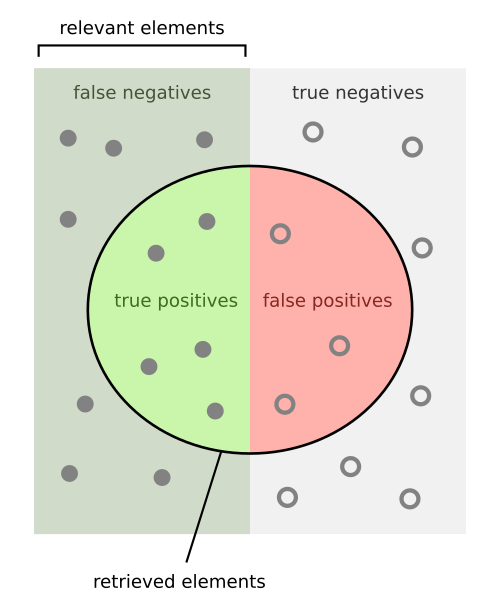

### Accuracy

**Accuracy** - доля правильно классифицированных объектов:

$$
Accuracy=\frac{TP+TN}{TP+TN+FP+FN}.
$$

В многоклассовой классификации это доля объектов, для которых предсказанный класс совпал с истинным. Accuracy легко интерпретировать, но при сильном дисбалансе классов она может скрывать плохое качество на редких классах.

### Precision

**Precision** (*точность положительных предсказаний*) отвечает на вопрос: какая доля объектов, которые модель назвала положительными, действительно относится к положительному классу?

$$
Precision=\frac{TP}{TP+FP}.
$$

Высокий Precision означает, что модель редко ошибочно присваивает положительный класс. Эта метрика важна, когда ложноположительные срабатывания дороги.

### Recall

**Recall** (*полнота*) отвечает на вопрос: какую долю всех реальных положительных объектов модель смогла найти?

$$
Recall=\frac{TP}{TP+FN}.
$$

Высокий Recall означает, что модель пропускает мало положительных объектов. Эта метрика важна, когда ошибки пропуска критичны.

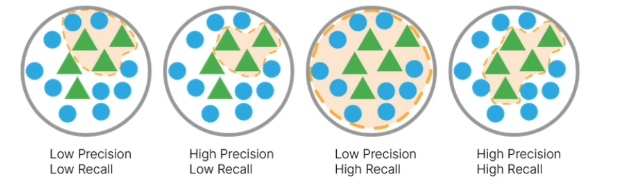

### F1-score

**F1-score** - гармоническое среднее Precision и Recall:

$$
F1=2\cdot\frac{Precision\cdot Recall}{Precision+Recall}
=\frac{2TP}{2TP+FP+FN}.
$$

F1 одновременно учитывает ложноположительные и ложноотрицательные ошибки. Он особенно полезен, когда важно сочетание Precision и Recall. Ни одна метрика не является универсальной: выбор зависит от того, какие ошибки наиболее важны в конкретной задаче.

### Усреднение: `macro` и `weighted`

В многоклассовой задаче Precision, Recall и F1 сначала рассчитываются отдельно для каждого класса.

- **Macro average** - простое среднее по классам. Каждый класс имеет одинаковый вес независимо от числа примеров.
- **Weighted average** - среднее по классам с весами, пропорциональными количеству истинных объектов класса (*support*).
- **Micro average** - сначала суммируются TP, FP и FN по всем классам, затем по суммам вычисляется метрика. Для обычной однозначной многоклассовой классификации micro-F1 совпадает с Accuracy.

Если классы представлены неравномерно, weighted average сильнее отражает качество на частых классах, а macro average позволяет увидеть, насколько равномерно модель работает по всем классам.

## Матрица ошибок (Confusion Matrix)

**Матрица ошибок** показывает, какие истинные классы модель относит к каким предсказанным классам. Для десяти классов MNIST она имеет размер $10\times10$.

В `sklearn.metrics.confusion_matrix` строки соответствуют **истинным классам**, а столбцы - **предсказанным**. Элемент $C_{i,j}$ показывает количество изображений класса $i$, которые модель отнесла к классу $j$.

- Значения на главной диагонали - правильные предсказания.
- Внедиагональные элементы - ошибки.
- Большие значения вне диагонали показывают пары цифр, которые модель часто путает.

Матрица ошибок дополняет общие метрики: два классификатора с одинаковой Accuracy могут совершать разные ошибки.

## Подготовка среды и данных

В работе используем набор данных **MNIST** - коллекцию изображений рукописных цифр от 0 до 9. Каждое изображение имеет размер $28\times28$ пикселей и относится к одному из десяти классов.

Используемые библиотеки: `torchvision.datasets.MNIST` для загрузки, `torchvision.transforms` для преобразования изображений, `DataLoader` для формирования батчей, PyTorch Lightning для организации обучения, `scikit-learn` для метрик и Matplotlib для визуализации.

Установка `torch` и `torchvision` должна соответствовать используемой версии CUDA или CPU-сборке PyTorch. Если остальные библиотеки отсутствуют, установите их согласно настройкам учебного окружения.

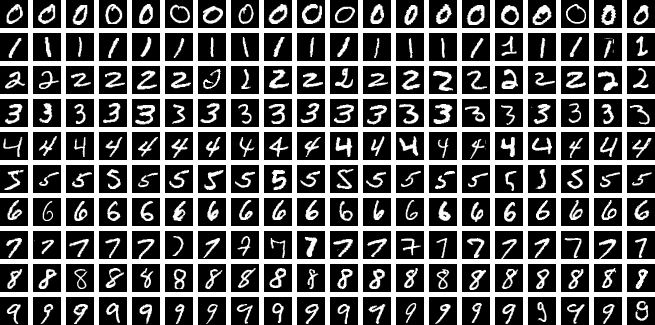

## Воспроизводимость и параметры эксперимента

Как и в лабораторной работе № 0, зафиксируем основные источники случайности. Это помогает сравнивать архитектуры и настройки в одинаковых условиях.

В MNIST случайность используется при разделении train/validation, перемешивании батчей и применении аугментаций. Полная побитовая воспроизводимость на любом оборудовании не гарантируется, но фиксированный seed уменьшает случайные различия между запусками.

In [6]:
# Фиксируем seed и задаём основные гиперпараметры эксперимента в одном месте.
from pathlib import Path
import random

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
VALIDATION_SHARE = 0.20
DATA_DIR = Path("./data")

DATA_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

## Загрузка и визуализация MNIST

MNIST содержит обучающую часть из 60 000 изображений и отдельную тестовую часть из 10 000 изображений. Внутри обучающей части мы дополнительно выделим validation.

Сначала загрузим обучающую часть без сложных преобразований и посмотрим на исходные изображения. Каждый объект состоит из изображения и целочисленной метки от 0 до 9.

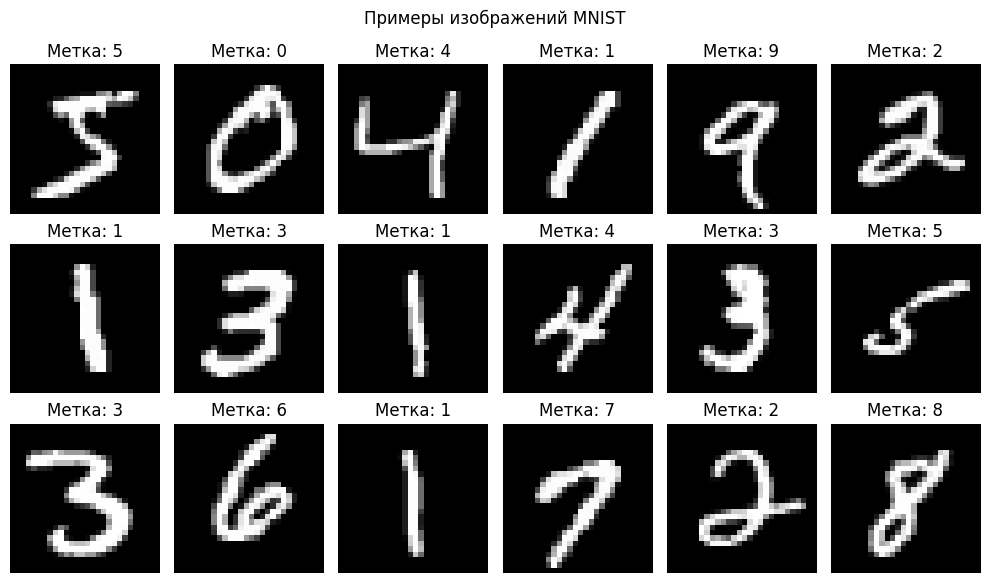

Размер обучающей части: 60000
Форма одного изображения: (1, 28, 28)


In [7]:
# Загружаем MNIST для первичного просмотра и выводим несколько изображений с метками.
from torchvision import datasets, transforms

preview_dataset = datasets.MNIST(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

fig, axes = plt.subplots(3, 6, figsize=(10, 6))
for index, ax in enumerate(axes.flat):
    image_tensor, label = preview_dataset[index]
    ax.imshow(image_tensor.squeeze(0), cmap="gray")
    ax.set_title(f"Метка: {label}")
    ax.axis("off")

fig.suptitle("Примеры изображений MNIST")
plt.tight_layout()
plt.show()

print("Размер обучающей части:", len(preview_dataset))
print("Форма одного изображения:", tuple(preview_dataset[0][0].shape))

### Баланс классов

В наборе представлены десять цифр. До обучения полезно проверить, сколько примеров каждого класса содержится в обучающей части. Это поможет понять, насколько сбалансирована задача.

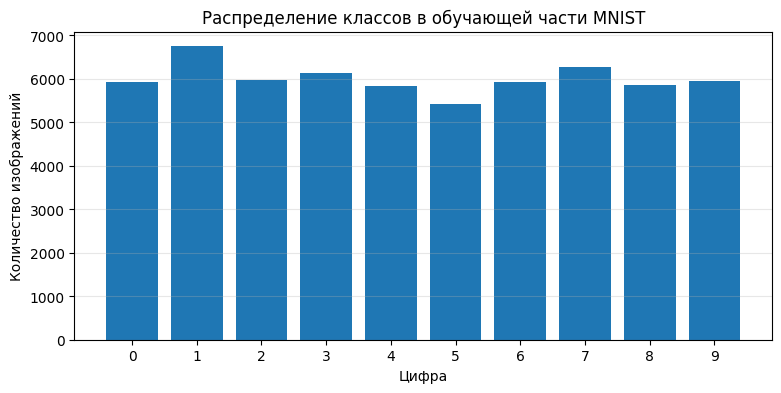

{'0': 5923, '1': 6742, '2': 5958, '3': 6131, '4': 5842, '5': 5421, '6': 5918, '7': 6265, '8': 5851, '9': 5949}


In [8]:
# Подсчитываем количество объектов каждого класса в исходной обучающей части MNIST.
class_names = [str(class_index) for class_index in range(10)]
initial_class_counts = torch.bincount(preview_dataset.targets, minlength=10).numpy()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(class_names, initial_class_counts)
ax.set_xlabel("Цифра")
ax.set_ylabel("Количество изображений")
ax.set_title("Распределение классов в обучающей части MNIST")
ax.grid(axis="y", alpha=0.3)
plt.show()

print(dict(zip(class_names, initial_class_counts.tolist())))

## Преобразования изображений и аугментации

Нейронная сеть получает числовой тензор, поэтому изображение нужно преобразовать из формата PIL в тензор. Для этого используем `torchvision.transforms`.

- `ToTensor()` переводит изображение в тензор формы `(1, 28, 28)` и масштабирует пиксели в диапазон `[0, 1]`;
- `Normalize(mean, std)` нормализует значения пикселей;
- `transforms.Lambda(torch.flatten)` преобразует матрицу пикселей в одномерный вектор длины 784.

Для MNIST часто используют среднее и стандартное отклонение, близкие к `0.1307` и `0.3081`. Нормализация должна быть одинаковой для train, validation и test.

### Аугментации

**Аугментация** - искусственное преобразование обучающих примеров, увеличивающее разнообразие входных данных. Для изображений это могут быть небольшие повороты, сдвиги и масштабирование.

Для рукописных цифр допустимы небольшие повороты и сдвиги. Слишком сильные преобразования могут менять смысл изображения. Поэтому аугментации применяются только к train, а validation и test сохраняются без случайных искажений.

В этой работе используем небольшой `RandomAffine`. Преобразование применяется при загрузке объекта и не создаёт новые файлы изображений на диске.

In [ ]:
# Задаём разные преобразования для обучения и оценки: аугментация включена только для train.
NORMALIZE_MEAN = (0.1307,)
NORMALIZE_STD = (0.3081,)

train_transform = transforms.Compose(
    [
        # Случайный поворот, случайное смещение относительно центра и случайный масштаб.
        transforms.RandomAffine(
            degrees=10,
            translate=(0.08, 0.08),
            scale=(0.90, 1.10),
        ),
        transforms.ToTensor(),
        transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
        transforms.Lambda(torch.flatten),
    ]
)

evaluation_transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
        transforms.Lambda(torch.flatten),
    ]
)

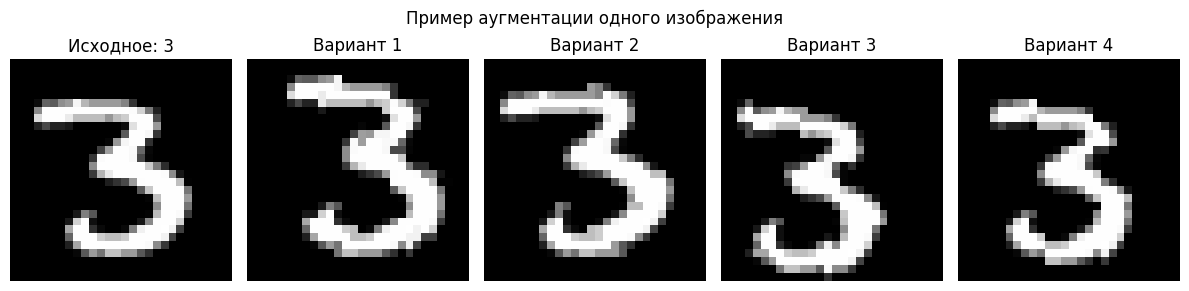

In [10]:
# Сравниваем исходное изображение и несколько случайных вариантов после аугментации.
train_aug_preview = datasets.MNIST(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=train_transform,
)

sample_index = 12
original_image, original_label = preview_dataset[sample_index]

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
axes[0].imshow(original_image.squeeze(0), cmap="gray")
axes[0].set_title(f"Исходное: {original_label}")
axes[0].axis("off")

# Повторный вызов датасета может вернуть другой случайный вариант этого изображения.
for view_index in range(1, 5):
    augmented_vector, _ = train_aug_preview[sample_index]
    augmented_image = (
        augmented_vector.reshape(28, 28) * NORMALIZE_STD[0] + NORMALIZE_MEAN[0]
    )
    axes[view_index].imshow(augmented_image, cmap="gray", vmin=0, vmax=1)
    axes[view_index].set_title(f"Вариант {view_index}")
    axes[view_index].axis("off")

plt.suptitle("Пример аугментации одного изображения")
plt.tight_layout()
plt.show()

### Преобразование изображения в вектор признаков

Полносвязный слой принимает вектор фиксированной длины, а не двумерное изображение. Для MNIST размером $28\times28$ преобразование `transforms.Lambda(torch.flatten)` формирует вектор из 784 элементов.

При этом пространственное расположение пикселей явно не сохраняется в форме матрицы: модель получает последовательность чисел. Она может выучить связи между позициями пикселей через веса линейных слоёв, однако MLP не использует специальный механизм локальности и общих свёрточных фильтров, как CNN.

In [11]:
# Применяем преобразования к одному примеру и проверяем форму, тип и диапазон значений.
transformed_vector, transformed_label = train_aug_preview[0]

print("Форма вектора:", tuple(transformed_vector.shape))
print("Тип данных:", transformed_vector.dtype)
print("Метка класса:", transformed_label)
print("Минимум после нормализации:", float(transformed_vector.min()))
print("Максимум после нормализации:", float(transformed_vector.max()))

Форма вектора: (784,)
Тип данных: torch.float32
Метка класса: 5
Минимум после нормализации: -0.4242129623889923
Максимум после нормализации: 2.821486711502075


**Небольшое задание.** Проверьте, что `transforms.Lambda(torch.flatten)` превращает `(1, 28, 28)` в `(784,)`. Какой будет форма батча из 64 таких объектов? Почему вход `nn.Linear` должен содержать 784 признака?

## Разделение на train, validation и test

- **train** используется для вычисления градиентов и обновления параметров;
- **validation** используется для наблюдения за качеством и выбора настроек;
- **test** используется для итоговой оценки уже выбранной модели.

Выделим 20% официальной обучающей части MNIST под validation. Официальную тестовую часть не используем до финальной оценки.

Аугментации применяются только к train. Поэтому создадим два объекта MNIST для одних и тех же обучающих изображений: один с аугментациями, другой без них. Они будут использовать одинаковые индексы, но разные преобразования.

In [ ]:
# Разделяем обучающую часть MNIST на train и validation, сохраняя test отдельно.
from torch.utils.data import DataLoader, Subset

train_aug_full = datasets.MNIST(
    root=DATA_DIR, train=True, download=True, transform=train_transform
)
train_eval_full = datasets.MNIST(
    root=DATA_DIR, train=True, download=True, transform=evaluation_transform
)
test_dataset = datasets.MNIST(
    root=DATA_DIR, train=False, download=True, transform=evaluation_transform
)

# Генератор с фиксированным seed делает разделение воспроизводимым.
split_generator = torch.Generator().manual_seed(SEED)
permuted_indices = torch.randperm(
    len(train_aug_full), generator=split_generator
).tolist()

validation_size = int(len(permuted_indices) * VALIDATION_SHARE)
validation_indices = permuted_indices[:validation_size]
train_indices = permuted_indices[validation_size:]

# Для train используем датасет с аугментациями, а для validation - без них.
train_dataset = Subset(train_aug_full, train_indices)
validation_dataset = Subset(train_eval_full, validation_indices)

print("Train:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Test:", len(test_dataset))

Train: 48000
Validation: 12000
Test: 10000


In [13]:
# Создаём DataLoader и проверяем формы батча изображений и меток.
pin_memory = device.type == "cuda"

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=pin_memory,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory,
)

features_batch, labels_batch = next(iter(train_loader))
print("Форма признаков:", tuple(features_batch.shape))
print("Форма меток:", tuple(labels_batch.shape))
print("Тип признаков:", features_batch.dtype)
print("Тип меток:", labels_batch.dtype)

Форма признаков: (128, 784)
Форма меток: (128,)
Тип признаков: torch.float32
Тип меток: torch.int64


Ожидаемые формы полного батча:

- признаки: `(batch_size, 784)`;
- метки: `(batch_size,)`.

В последнем батче эпохи число объектов может быть меньше `batch_size`. Для `CrossEntropyLoss` метки должны быть целочисленными индексами классов типа `torch.long`.

Проверим, что все классы представлены после разделения.

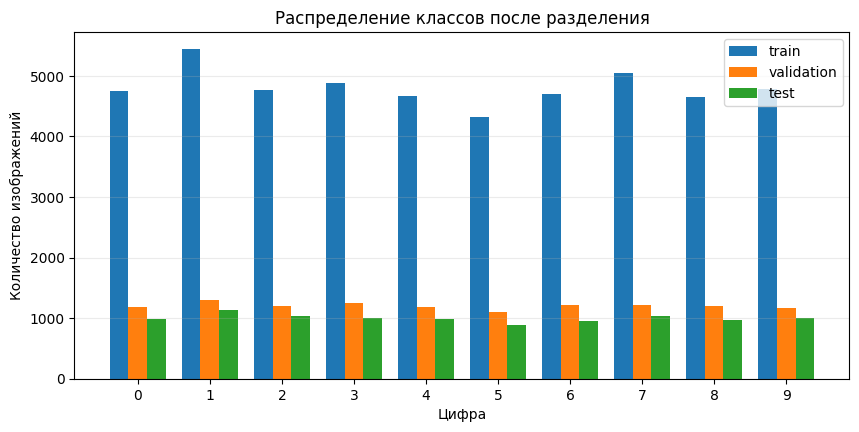

In [14]:
# Сравниваем распределение цифр в train, validation и test после разделения.
class_names = [str(class_index) for class_index in range(10)]
split_counts = {
    "train": torch.bincount(
        train_aug_full.targets[torch.tensor(train_indices)], minlength=10
    ).numpy(),
    "validation": torch.bincount(
        train_eval_full.targets[torch.tensor(validation_indices)], minlength=10
    ).numpy(),
    "test": torch.bincount(test_dataset.targets, minlength=10).numpy(),
}

fig, ax = plt.subplots(figsize=(10, 4.5))
x_positions = np.arange(10)
bar_width = 0.26

for offset, (split_name, counts) in enumerate(split_counts.items()):
    ax.bar(
        x_positions + (offset - 1) * bar_width,
        counts,
        width=bar_width,
        label=split_name,
    )

ax.set_xticks(x_positions)
ax.set_xticklabels(class_names)
ax.set(
    xlabel="Цифра",
    ylabel="Количество изображений",
    title="Распределение классов после разделения",
)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.show()

## Архитектура MLP на PyTorch

Для MNIST входной вектор имеет 784 значения, а число классов равно 10. Между входом и выходом можно расположить один или несколько скрытых слоёв.

В следующем каркасе нужно самостоятельно реализовать прямой проход. Слои уже зарегистрированы как атрибуты объекта, поэтому PyTorch будет учитывать их параметры при вызове `model.parameters()`.

В `forward()` должны последовательно выполняться линейное преобразование, нелинейность и следующий линейный слой. На выходе верните **логиты** формы `(batch_size, 10)`. Не применяйте Softmax перед `CrossEntropyLoss`.

In [ ]:
# Каркас MLP: реализуйте прямой проход через два скрытых слоя и выходной слой.
class MNISTMLP(nn.Module):
    def __init__(
        self,
        in_features: int = 784,
        hidden_features: tuple[int, ...] = (256, 128),
        num_classes: int = 10,
    ) -> None:
        # Определите необходимые слои и сохраните их как атрибуты объекта.
        super().__init__()
        ...

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Опишите прямой проход и верните логиты формы (batch_size, num_classes).
        ...

После реализации проверьте, что модель принимает батч формы `(64, 784)` и возвращает логиты формы `(64, 10)`. Число строк выхода должно совпадать с числом объектов во входном батче, а число столбцов - с количеством классов.

Для слоя `nn.Linear(in_features, out_features)` число обучаемых параметров равно `in_features * out_features + out_features`.

In [16]:
student_model = MNISTMLP().to(device)
sample_batch = torch.randn(64, 784, device=device)
sample_logits = student_model(sample_batch)
print("Форма выхода:", tuple(sample_logits.shape))
print(
    "Число параметров:",
    sum(p.numel() for p in student_model.parameters() if p.requires_grad),
)

Форма выхода: (64, 10)
Число параметров: 235146


## Обучение через PyTorch Lightning

В лабораторной работе № 0 мы рассмотрели, что `LightningModule` описывает модель, шаги обучения и оптимизатор, а `Trainer` организует общий цикл. Здесь используем тот же подход, но сам процесс обучения абстрагирован от реализации модели в классе `LitModel`. Он позволяет обучать любую модель для задачи классификации.

In [ ]:
%pip install lightning -qU

In [43]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

In [ ]:
# Создаём и обучаем модель с помощью Lightning.
from templates.lit import LitModel

model = LitModel(
    model=MNISTMLP,
    in_features=28 * 28,
    hidden_features=(256, 128),
    num_classes=10,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

metrics = model.fit(
    train_loader=train_loader,
    validation_loader=validation_loader,
    epochs=MAX_EPOCHS,
    patience=3,
    seed=SEED,
)

model = model.to(device)

best_model = model.network.eval()

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (2 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

### Анализ графиков обучения

Графики показывают не только итоговое качество, но и динамику обучения. При корректном обучении train loss обычно уменьшается. Validation loss также может уменьшаться, но затем способен выйти на плато или начать расти.

Если train loss продолжает снижаться, а validation loss растёт, это признак возможного переобучения. В таком случае стоит проверить размер модели, силу регуляризации, аугментации и момент ранней остановки.

,train_loss,train_accuracy,val_loss,val_accuracy
epoch,,,,
0,0.546511,0.828021,0.146904,0.957167
1,0.210851,0.935458,0.098377,0.968833
2,0.171439,0.947062,0.098930,0.968833
3,0.146770,0.954208,0.072479,0.977750
4,0.129689,0.960229,0.072390,0.976167
5,0.119949,0.961875,0.064607,0.979750
6,0.111277,0.965146,0.057865,0.982000
7,0.105151,0.966958,0.059373,0.980833
8,0.101364,0.968521,0.054767,0.981917


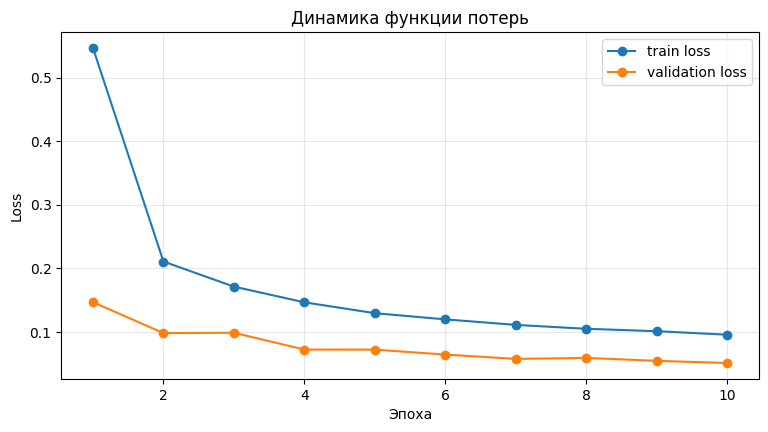

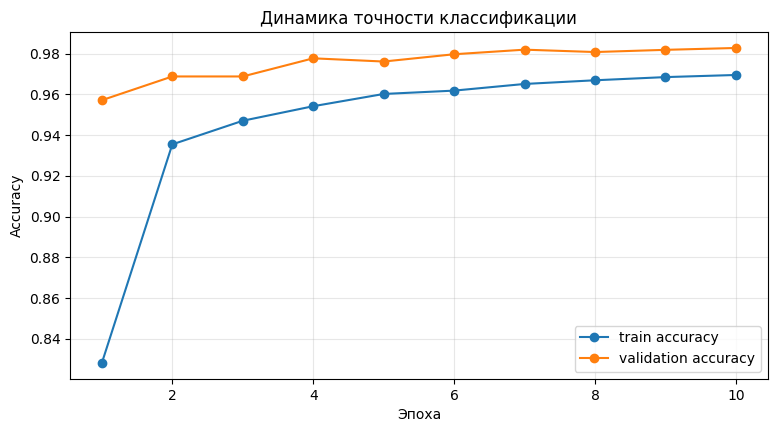

In [22]:
# Для каждой эпохи берём последнее доступное значение каждой метрики, пропуски игнорируются.
epoch_metrics = metrics.groupby("epoch")[
    ["train_loss", "train_accuracy", "val_loss", "val_accuracy"]
].last()

display(epoch_metrics)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    epoch_metrics.index + 1, epoch_metrics["train_loss"], marker="o", label="train loss"
)
ax.plot(
    epoch_metrics.index + 1,
    epoch_metrics["val_loss"],
    marker="o",
    label="validation loss",
)
ax.set(xlabel="Эпоха", ylabel="Loss", title="Динамика функции потерь")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    epoch_metrics.index + 1,
    epoch_metrics["train_accuracy"],
    marker="o",
    label="train accuracy",
)
ax.plot(
    epoch_metrics.index + 1,
    epoch_metrics["val_accuracy"],
    marker="o",
    label="validation accuracy",
)
ax.set(xlabel="Эпоха", ylabel="Accuracy", title="Динамика точности классификации")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**Исследование.** Определите по графикам эпоху с минимальным validation loss. Сравните train и validation accuracy. Измените число нейронов в скрытых слоях и повторите обучение. Как изменение архитектуры повлияло на разрыв между обучающей и валидационной метриками?

## Метрики с помощью scikit-learn

Lightning удобно использовать для организации обучения и журналирования, а `scikit-learn` - для подробной оценки результата. Для `classification_report` нужны два массива одинаковой длины:

- `y_true` - истинные метки;
- `y_pred` - предсказанные классы.

Соберём предсказания для всех объектов тестовой выборки. Во время инференса отключим вычисление градиентов и переведём модель в режим `eval()`.

In [35]:
# Получаем предсказанные классы и истинные метки для всей тестовой выборки.
@torch.inference_mode()
def collect_predictions(
    model: nn.Module,
    loader: DataLoader,
    target_device: torch.device,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Возвращает истинные метки, предсказания и вероятности классов."""
    model.eval()

    all_targets: list[np.ndarray] = []
    all_predictions: list[np.ndarray] = []
    all_probabilities: list[np.ndarray] = []

    for features, labels in loader:
        # Переносим признаки на то же устройство, где расположена модель.
        features = features.to(target_device)

        # Модель возвращает логиты; Softmax преобразует их в вероятности для анализа.
        logits = model(features)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)

        all_targets.append(labels.cpu().numpy())
        all_predictions.append(predictions.cpu().numpy())
        all_probabilities.append(probabilities.cpu().numpy())

    return (
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        np.concatenate(all_probabilities),
    )


y_true, y_pred, y_probabilities = collect_predictions(best_model, test_loader, device)

print("Количество тестовых объектов:", len(y_true))
print("Форма матрицы вероятностей:", y_probabilities.shape)
print("Первые десять истинных меток:", y_true[:10])
print("Первые десять предсказаний:", y_pred[:10])

Количество тестовых объектов: 10000
Форма матрицы вероятностей: (10000, 10)
Первые десять истинных меток: [7 2 1 0 4 1 4 9 5 9]
Первые десять предсказаний: [7 2 1 0 4 1 4 9 5 9]


In [36]:
# Рассчитываем Accuracy, macro/weighted Precision, Recall, F1-score и подробный отчёт.
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_recall_fscore_support,
)


accuracy = accuracy_score(y_true, y_pred)

precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)
precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
    y_true, y_pred, average="weighted", zero_division=0
)

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {precision_macro:.4f}")
print(f"Macro Recall: {recall_macro:.4f}")
print(f"Macro F1-score: {f1_macro:.4f}")
print(f"Weighted Precision: {precision_weighted:.4f}")
print(f"Weighted Recall: {recall_weighted:.4f}")
print(f"Weighted F1-score: {f1_weighted:.4f}")

print("\nПодробный отчёт:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(10)),
        target_names=class_names,
        digits=4,
        zero_division=0,
    )
)

Accuracy: 0.9828
Macro Precision: 0.9828
Macro Recall: 0.9826
Macro F1-score: 0.9826
Weighted Precision: 0.9829
Weighted Recall: 0.9828
Weighted F1-score: 0.9828

Подробный отчёт:
              precision    recall  f1-score   support

           0     0.9898    0.9908    0.9903       980
           1     0.9912    0.9974    0.9943      1135
           2     0.9874    0.9884    0.9879      1032
           3     0.9920    0.9832    0.9876      1010
           4     0.9864    0.9623    0.9742       982
           5     0.9788    0.9854    0.9821       892
           6     0.9853    0.9802    0.9827       958
           7     0.9796    0.9796    0.9796      1028
           8     0.9825    0.9805    0.9815       974
           9     0.9545    0.9782    0.9662      1009

    accuracy                         0.9828     10000
   macro avg     0.9828    0.9826    0.9826     10000
weighted avg     0.9829    0.9828    0.9828     10000



В `classification_report` для каждой цифры отображаются Precision, Recall, F1-score и `support` - количество истинных объектов этого класса.

`macro avg` даёт одинаковый вес каждой цифре. `weighted avg` учитывает частоту классов. Для MNIST эти показатели часто близки, но в более несбалансированных задачах различие может быть заметнее.

**Задание.** Выберите две цифры, для которых F1-score оказался наиболее низким. Посмотрите, сколько примеров каждого класса было в test. Предположите, с какими визуально похожими цифрами модель может их путать.

## Confusion Matrix

Построим матрицу ошибок с помощью `sklearn.metrics.confusion_matrix`. По строкам расположены истинные цифры, по столбцам - предсказанные. Нормализованный вариант показывает долю предсказаний внутри каждого истинного класса и позволяет сравнивать классы с разным количеством примеров.

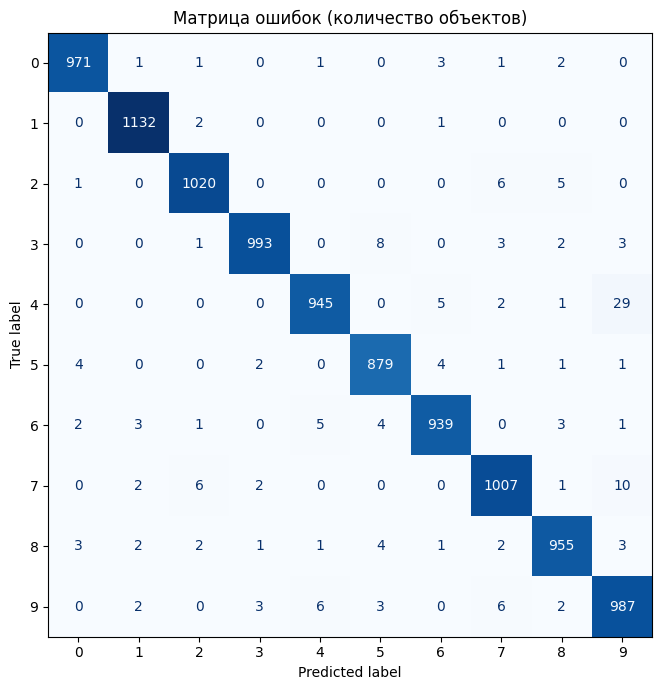

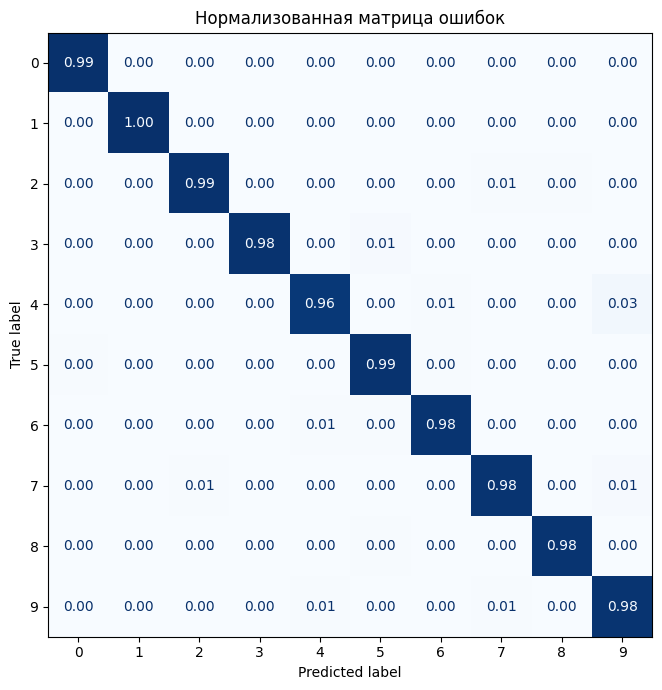

In [37]:
# Строим обычную и нормализованную матрицы ошибок для десяти классов MNIST.
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix


labels = list(range(10))
confusion = confusion_matrix(y_true, y_pred, labels=labels)
confusion_normalized = confusion_matrix(y_true, y_pred, labels=labels, normalize="true")

fig, ax = plt.subplots(figsize=(8, 7))
confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=class_names,
)
confusion_display.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Матрица ошибок (количество объектов)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
normalized_display = ConfusionMatrixDisplay(
    confusion_matrix=confusion_normalized,
    display_labels=class_names,
)
normalized_display.plot(ax=ax, cmap="Blues", colorbar=False, values_format=".2f")
ax.set_title("Нормализованная матрица ошибок")
plt.tight_layout()
plt.show()

При просмотре матрицы ошибок обратите внимание на внедиагональные ячейки. Например, если в строке `4` и столбце `9` значение велико, это значит, что часть настоящих четвёрок модель ошибочно распознала как девятки.

Для бинарной задачи из матрицы можно было бы получить TP, TN, FP и FN для выбранного положительного класса. В многоклассовой задаче эти показатели рассчитываются для каждого класса по схеме «этот класс против всех остальных».

## Визуализация ошибочных предсказаний

Численные метрики не всегда показывают, почему модель ошиблась. Посмотрим на изображения, для которых предсказанная цифра не совпала с истинной. Так можно заметить неоднозначные написания, необычные наклоны или визуальное сходство двух классов.

Число ошибочных предсказаний: 172


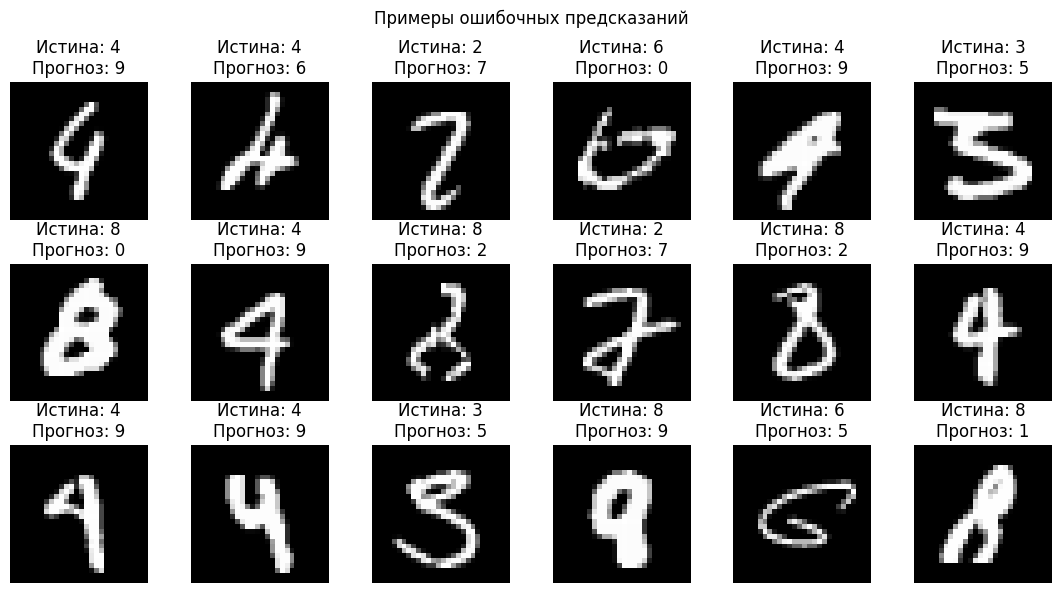

In [38]:
# Находим ошибки классификации и показываем изображения с истинной и предсказанной метками.
wrong_indices = np.flatnonzero(y_true != y_pred)
print("Число ошибочных предсказаний:", len(wrong_indices))

number_to_show = min(18, len(wrong_indices))
selected_wrong = wrong_indices[:number_to_show]

fig, axes = plt.subplots(3, 6, figsize=(11, 6))
for ax in axes.flat:
    ax.axis("off")

for ax, sample_index in zip(axes.flat, selected_wrong):
    # Восстанавливаем изображение 28 × 28 из нормализованного вектора.
    normalized_image, _ = test_dataset[int(sample_index)]
    image = normalized_image.reshape(28, 28) * NORMALIZE_STD[0] + NORMALIZE_MEAN[0]

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"Истина: {int(y_true[sample_index])}\nПрогноз: {int(y_pred[sample_index])}"
    )
    ax.axis("off")

fig.suptitle("Примеры ошибочных предсказаний")
plt.tight_layout()
plt.show()

**Исследование.** Рассмотрите несколько ошибочных примеров. Какие особенности написания могли сбить классификатор? Какие цифры модель чаще всего путает согласно матрице ошибок? Совпадает ли визуальное наблюдение с числами в матрице?

## Интерактивное распознавание нарисованной цифры

Используем обученную модель для распознавания цифры, которую можно нарисовать мышью. Виджет основан на `ipywidgets` и `ipycanvas`.

MNIST хранит светлые штрихи цифры на тёмном фоне. В canvas ниже фон белый, а линия чёрная, поэтому перед подачей в модель изображение нужно инвертировать. Затем выделим ограничивающую рамку цифры, уменьшим её до области не более $20\times20$ пикселей, поместим по центру холста $28\times28$ и применим ту же нормализацию, что и к test.

Это приближённое согласование с форматом MNIST: реальные изображения MNIST дополнительно центрировались по центру масс, поэтому качество на рисунках пользователя может отличаться от тестовой метрики.

In [ ]:
%pip install ipycanvas -qU

In [ ]:
try:
    from google.colab import output

    output.enable_custom_widget_manager()
except:
    pass

In [39]:
# Определяем интерактивный canvas для рисования цифр и передачи изображения в callback.

from typing import Callable

import ipywidgets as widgets
from ipycanvas import Canvas
from IPython.display import display, clear_output

from PIL import Image, ImageOps


class DrawableCanvas:
    """Canvas для рисования мышью с передачей готового PIL-изображения в callback."""

    def __init__(self, width: int = 280, height: int = 280) -> None:
        self.width = width
        self.height = height
        self._is_drawing = False
        self._callback: Callable[[Image.Image], None] | None = None

        # Canvas синхронизирует пиксели с Python, чтобы их можно было получить как изображение.
        self._canvas = Canvas(width=width, height=height, sync_image_data=True)
        self._canvas.line_width = 15
        self._canvas.stroke_style = "black"
        self._canvas.line_cap = "round"
        self._canvas.line_join = "round"
        self._canvas.fill_style = "white"
        self._canvas.fill_rect(0, 0, width, height)

        # Контейнер ограничивает размер виджета и рисует рамку вокруг рабочей области.
        canvas_container = widgets.Box(
            [self._canvas],
            layout=widgets.Layout(
                width=f"{width}px",
                height=f"{height}px",
                overflow="hidden",
                border="1px solid lightgray",
            ),
        )

        # Регистрируем обработчики мыши для начала, продолжения и завершения штриха.
        self._canvas.on_mouse_down(self._handle_mousedown)
        self._canvas.on_mouse_move(self._handle_mousemove)
        self._canvas.on_mouse_up(self._handle_mouseup)
        self._canvas.on_mouse_out(self._handle_mouseout)

        # Кнопка распознавания передаёт текущее изображение в callback.
        proceed_button = widgets.Button(description="Распознать")
        proceed_button.on_click(self._get_pil_image)

        # Кнопка очистки возвращает белый фон.
        clear_button = widgets.Button(description="Очистить")
        clear_button.on_click(self._clear)

        self._widget = widgets.VBox(
            [canvas_container, widgets.HBox([proceed_button, clear_button])],
            layout=widgets.Layout(border="1px solid lightgray", padding="8px"),
        )

    def set_callback(self, callback: Callable[[Image.Image], None]) -> None:
        """Устанавливает функцию, которая получит готовое изображение."""
        self._callback = callback

    def _handle_mousedown(self, x: float, y: float) -> None:
        """Начинает новый штрих в позиции нажатия мыши."""
        self._is_drawing = True
        self._canvas.begin_path()
        self._canvas.move_to(x, y)

    def _handle_mousemove(self, x: float, y: float) -> None:
        """Продолжает штрих, пока пользователь удерживает кнопку мыши."""
        if self._is_drawing:
            self._canvas.line_to(x, y)
            self._canvas.stroke()

    def _handle_mouseup(self, x: float, y: float) -> None:
        """Завершает штрих при отпускании кнопки мыши."""
        self._is_drawing = False

    def _handle_mouseout(self, x: float, y: float) -> None:
        """Завершает штрих, если курсор покинул область canvas."""
        self._is_drawing = False

    def _clear(self, _button: widgets.Button) -> None:
        """Очищает canvas и восстанавливает белый фон."""
        self._canvas.clear()
        self._canvas.fill_style = "white"
        self._canvas.fill_rect(0, 0, self.width, self.height)

    def _get_pil_image(self, _button: widgets.Button) -> None:
        """Преобразует содержимое canvas в PIL.Image и вызывает callback."""
        if self._callback is None:
            return

        image_array = np.asarray(self._canvas.get_image_data(), dtype=np.uint8)
        pil_image = Image.fromarray(image_array, mode="RGBA")
        self._callback(pil_image)

    def _repr_mimebundle_(self, **kwargs):
        """Возвращает MIME-описание виджета для Jupyter."""
        plaintext = repr(self._widget)
        if len(plaintext) > 110:
            plaintext = plaintext[:110] + "…"

        return {
            "text/plain": plaintext,
            "application/vnd.jupyter.widget-view+json": {
                "version_major": 2,
                "version_minor": 0,
                "model_id": self._widget._model_id,
            },
        }

### Предобработка нарисованного изображения

Модель ожидает вектор длины 784, нормализованный так же, как изображения MNIST. Перед инференсом:

1. переведём изображение в оттенки серого;
2. инвертируем цвета, чтобы цифра была светлой на тёмном фоне;
3. обрежем пустые поля вокруг штрихов;
4. уменьшим изображение с сохранением пропорций до размера не более $20\times20$;
5. поместим его по центру изображения $28\times28$;
6. применим `evaluation_transform`.

In [40]:
# Преобразуем изображение из canvas в формат, близкий к исходным изображениям MNIST.
def preprocess_canvas_image(image: Image.Image) -> Image.Image:
    """Возвращает изображение 28 × 28 с белой цифрой на чёрном фоне."""
    grayscale = image.convert("L")

    # В canvas фон белый, а штрихи чёрные; MNIST использует противоположную полярность.
    inverted = ImageOps.invert(grayscale)

    # Удаляем пустые поля вокруг цифры, чтобы она занимала значимую часть изображения.
    bounding_box = inverted.getbbox()
    if bounding_box is None:
        return Image.new("L", (28, 28), color=0)

    cropped = inverted.crop(bounding_box)

    # Сохраняем пропорции и вписываем цифру в область 20 × 20.
    cropped.thumbnail((20, 20), Image.Resampling.LANCZOS)

    # Создаём итоговое изображение 28 × 28 и размещаем цифру по центру.
    result = Image.new("L", (28, 28), color=0)
    offset_x = (28 - cropped.width) // 2
    offset_y = (28 - cropped.height) // 2
    result.paste(cropped, (offset_x, offset_y))

    return result

In [41]:
# Подключаем callback: преобразуем рисунок, запускаем модель и выводим вероятности десяти цифр.
import pandas as pd


prediction_output = widgets.Output()


@torch.inference_mode()
def predict_drawn_digit(image: Image.Image) -> None:
    """Распознаёт нарисованную цифру и выводит вероятности классов."""
    processed_image = preprocess_canvas_image(image)

    # evaluation_transform повторяет нормализацию и преобразование в вектор из обучающего конвейера.
    input_tensor = evaluation_transform(processed_image).unsqueeze(0).to(device)

    best_model.eval()
    logits = best_model(input_tensor)
    probabilities = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()

    predicted_digit = int(np.argmax(probabilities))
    sorted_indices = np.argsort(probabilities)[::-1]

    with prediction_output:
        clear_output(wait=True)
        print(f"Предсказанная цифра: {predicted_digit}")
        print(f"Вероятность выбранного класса: {probabilities[predicted_digit]:.2%}")

        fig, ax = plt.subplots(figsize=(2.5, 2.5))
        ax.imshow(processed_image, cmap="gray", vmin=0, vmax=255)
        ax.set_title("Изображение после предобработки")
        ax.axis("off")
        plt.show()

        probability_table = pd.DataFrame(
            {
                "Цифра": sorted_indices.astype(int),
                "Вероятность": probabilities[sorted_indices],
            }
        )
        display(probability_table.style.format({"Вероятность": "{:.2%}"}))


digit_canvas = DrawableCanvas(width=280, height=280)
digit_canvas.set_callback(predict_drawn_digit)

display(digit_canvas)
display(prediction_output)

Output()

Попробуйте нарисовать несколько цифр разным почерком. Сравните предсказания и вероятности. Модель обучалась на изображениях MNIST, поэтому она может ошибаться на слишком крупных, наклонённых или необычно расположенных символах.

**Исследование.** Нарисуйте одну и ту же цифру несколько раз: крупно, мелко, с наклоном и со смещением. Меняется ли предсказание? Как это связано с аугментациями, использованными при обучении?

## Эксперименты с архитектурой

Теперь можно исследовать, как изменение архитектуры влияет на качество. Сравнивайте варианты при одинаковом разделении данных и близких условиях обучения.

Возможные направления:

- изменить размеры скрытых слоёв, например `(128, 64)`, `(256, 128)` или `(512, 256)`;
- сравнить ReLU, Sigmoid и Tanh;
- изменить `weight_decay`;
- сравнить графики train/validation loss и итоговые метрики на test.

Не меняйте сразу все параметры: иначе будет трудно понять, какой именно фактор повлиял на результат. После выбора модели тестовая выборка используется для итоговой оценки, а не для многократного подбора конфигурации.

In [ ]:
# Задайте собственную конфигурацию MLP для эксперимента и обучите её тем же способом.
experiment_config = {
    "in_features": 784,
    "hidden_sizes": (128, 64),  # Измените размеры скрытых слоёв.
    "num_classes": 10,
    "lr": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
}

## Контрольные вопросы

1. Что такое многослойный перцептрон и из каких основных частей он состоит?
2. Почему несколько линейных слоёв без функций активации эквивалентны одному линейному преобразованию?
3. Какую роль играют функции активации в MLP?
4. Чем отличаются ReLU, Sigmoid и Tanh? В каких диапазонах они возвращают значения?
5. Что такое затухание градиента и почему оно может возникать при использовании Sigmoid или Tanh?
6. Что такое взрыв градиента? Какие факторы могут приводить к его появлению?
7. Чем логиты отличаются от вероятностей классов?
8. Как работает Softmax и зачем из логитов вычитают их максимальное значение?
9. Почему перед `nn.CrossEntropyLoss` не нужно применять Softmax?
10. Что такое аугментация и почему её применяют только к обучающим данным?
11. Что измеряют Accuracy, Precision, Recall и F1-score?
12. Чем отличаются ошибки I и II рода?
13. Что означают macro average и weighted average в `classification_report`?
14. Как читать матрицу ошибок? Что обозначают её диагональные и внедиагональные элементы?
15. Почему MLP требует преобразования изображения MNIST в вектор признаков?
16. Почему качество на тестовой выборке следует оценивать после выбора конфигурации модели?